In [1]:
!pip install torchvision

In [2]:
import torch
import os
from torch.utils.data import DataLoader,Dataset
from torchvision import transforms
from PIL import Image


In [3]:
from google.colab import drive
# Mount Google Drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
class ImageProcessor:

    def __init__(self, root_dir_path, transformations=None):

        self.root_dir_path = root_dir_path
        self.transformations = transformations

        # List of paths for all images
        self.all_img_paths = [
            os.path.join(root_dir_path, img)
            for img in os.listdir(root_dir_path)
        ]
    def __len__(self):
      return len(self.all_img_paths)

    def __getitem__(self,indx):
      img_path = self.all_img_paths[indx]
      img = Image.open(img_path).convert("RGB")

      if self.transformations:
        img = self.transformations(img)

      return img

In [6]:
import zipfile
import os

zip_path = "/content/drive/MyDrive/Dataset_ap/img_align_celeba.zip"

extract_path = "/content/drive/MyDrive/Dataset_ap/"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

In [9]:
root_dir_path = "/content/drive/MyDrive/Dataset_ap/img_align_celeba"

transformations = transforms.Compose([
    transforms.CenterCrop(178), # 178x218 => 178x178
    transforms.Resize(64), # 64x64
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)) # [-1, 1]
])

In [10]:
dataset = ImageProcessor(root_dir_path, transformations)
print(f"loaded {len(dataset)} images")

loaded 202599 images


In [11]:
dataloader = DataLoader(dataset, batch_size=128, shuffle=True)

# Generator Network

In [12]:
import torch.nn as nn
import torch.optim as optim
import numpy as np

In [13]:
class Generator(nn.Module):
    def __init__(self, z_dim=100, img_channels=3): # 3 is for RGB
        super(Generator, self).__init__()

        # fully connected (dense) layers
        self.model = nn.Sequential(
            nn.Linear(z_dim, 256), # 100 => 256
            nn.ReLU(),

            nn.Linear(256, 512),
            nn.ReLU(),

            nn.Linear(512, 1024),
            nn.ReLU(),

            nn.Linear(1024, 64 * 64 * img_channels),
            nn.Tanh() # [-1, 1]
        )

    def forward(self, z):
        img = self.model(z)
        img = img.view(img.size(0), 3, 64, 64)
        return img

        # fake img => 64 x 64 x 3 x batch_size


# Discriminator Network

In [14]:
class Discriminator(nn.Module):
    def __init__(self, img_channels=3): # 3 is for RGB
        super(Discriminator, self).__init__()

        # fully connected (dense) layers
        self.model = nn.Sequential(
            nn.Flatten(), # 4D tensor => 1D

            nn.Linear(img_channels * 64 * 64, 1024),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Linear(1024, 512),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Linear(512, 256),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Linear(256, 1),
            nn.Sigmoid() # probability of being real/fake
        )

    def forward(self, img):
        return self.model(img)

In [15]:
GAN_loss = nn.BCELoss()   # binary cross entropy loss

generator = Generator()
g_optimizer = optim.Adam(generator.parameters(), lr=0.0002, betas=(0.5, 0.999))

discriminator = Discriminator()
d_optimizer = optim.Adam(discriminator.parameters(), lr=0.0002, betas=(0.5, 0.999))

In [16]:
import torch
# device
if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

print(f"device is {device}")

device is cuda


In [17]:
generator = generator.to(device)
discriminator = discriminator.to(device)

# Training the GAN

In [22]:
def train(generator,discriminator,dataloader,epochs = 10):
  for epoch in range(epochs):
    for i , imgs in enumerate(dataloader):
      real_imgs = imgs.to(device)
      batch_size = real_imgs.size(0)

      #creqate real imgs labels and fake imgs labels
      real_labels = torch.ones(batch_size,1).to(device) #[1,1,1,.....]
      fake_labels = torch.zeros(batch_size,1).to(device) #[0,0,0,.....]

      # train the discriminator
      d_optimizer.zero_grad()
      fake_imgs = generator(torch.randn(batch_size,100).to(device))

      real_loss = GAN_loss(discriminator(real_imgs),real_labels)
      fake_loss = GAN_loss(discriminator(fake_imgs.detach()),fake_labels)

      d_loss = (real_loss + fake_loss)/2

      d_loss.backward()
      d_optimizer.step()

      # train the generator
      g_optimizer.zero_grad()
      g_loss = GAN_loss(discriminator(fake_imgs),real_labels)

      g_loss.backward()
      g_optimizer.step()

      if i% 50 == 0:
        print(f"for epoch: {epoch+1}/{epochs}... batch: {i+1}... G-loss:{g_loss}.... D-loss: {d_loss}")

    # save generated imgs for each epoch
    save_generated_images(generator, epoch, device)

In [23]:
import matplotlib.pyplot as plt
import torchvision

def save_generated_images(generator, epoch, device, num_imgs=12):
    z = torch.randn(num_imgs, 100).to(device)
    generated_imgs = generator(z).detach().cpu()

    grid = torchvision.utils.make_grid(generated_imgs, nrow=4, normalize=True)

    plt.imshow(np.transpose(grid, (1, 2, 0)))
    plt.title(f"epoch {epoch+1}")
    plt.axis("off")
    plt.show()

for epoch: 1/10... batch: 1... G-loss:0.7736608982086182.... D-loss: 0.41133812069892883
for epoch: 1/10... batch: 51... G-loss:1.0946123600006104.... D-loss: 0.26912638545036316
for epoch: 1/10... batch: 101... G-loss:2.1351308822631836.... D-loss: 0.09964469075202942
for epoch: 1/10... batch: 151... G-loss:2.9144437313079834.... D-loss: 0.04068980738520622
for epoch: 1/10... batch: 201... G-loss:3.7191274166107178.... D-loss: 0.09716346114873886
for epoch: 1/10... batch: 251... G-loss:6.97222900390625.... D-loss: 3.7159197330474854
for epoch: 1/10... batch: 301... G-loss:4.230205535888672.... D-loss: 0.09158900380134583
for epoch: 1/10... batch: 351... G-loss:6.735241889953613.... D-loss: 0.019903136417269707
for epoch: 1/10... batch: 401... G-loss:3.795389413833618.... D-loss: 0.07320740073919296
for epoch: 1/10... batch: 451... G-loss:4.355706214904785.... D-loss: 0.05662313103675842
for epoch: 1/10... batch: 501... G-loss:4.029139995574951.... D-loss: 0.03507120907306671
for epoch

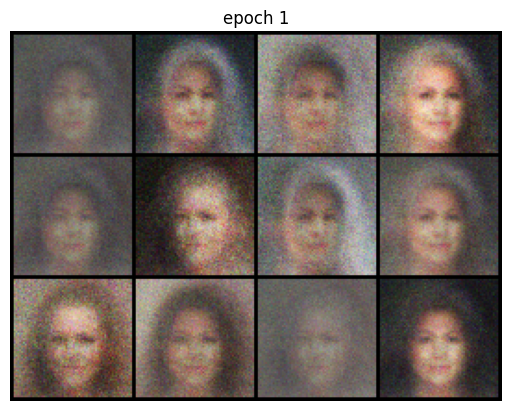

for epoch: 2/10... batch: 1... G-loss:3.5153281688690186.... D-loss: 0.23104923963546753
for epoch: 2/10... batch: 51... G-loss:4.703983306884766.... D-loss: 0.30167949199676514
for epoch: 2/10... batch: 101... G-loss:3.9321703910827637.... D-loss: 0.1611478179693222
for epoch: 2/10... batch: 151... G-loss:2.2401537895202637.... D-loss: 0.2139989137649536
for epoch: 2/10... batch: 201... G-loss:5.783875465393066.... D-loss: 0.30005693435668945
for epoch: 2/10... batch: 251... G-loss:2.7510013580322266.... D-loss: 0.13971179723739624
for epoch: 2/10... batch: 301... G-loss:3.7028756141662598.... D-loss: 0.1861913502216339
for epoch: 2/10... batch: 351... G-loss:4.953402519226074.... D-loss: 0.3623417615890503
for epoch: 2/10... batch: 401... G-loss:6.716401100158691.... D-loss: 0.2878406047821045
for epoch: 2/10... batch: 451... G-loss:2.829390525817871.... D-loss: 0.5951067805290222
for epoch: 2/10... batch: 501... G-loss:3.1813712120056152.... D-loss: 0.22582583129405975
for epoch: 2/

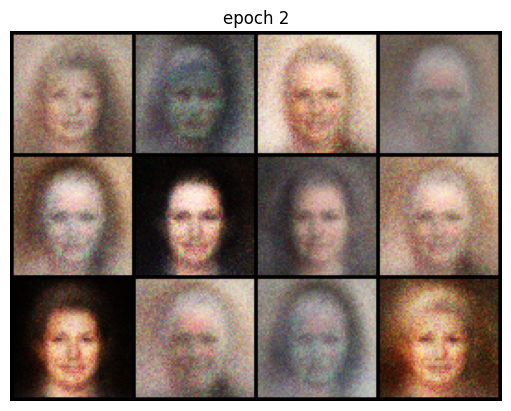

for epoch: 3/10... batch: 1... G-loss:2.5271010398864746.... D-loss: 0.41445696353912354
for epoch: 3/10... batch: 51... G-loss:2.508528232574463.... D-loss: 0.27410420775413513
for epoch: 3/10... batch: 101... G-loss:3.5892720222473145.... D-loss: 0.30806684494018555
for epoch: 3/10... batch: 151... G-loss:3.7069692611694336.... D-loss: 0.4747247099876404
for epoch: 3/10... batch: 201... G-loss:2.477897882461548.... D-loss: 0.34074342250823975
for epoch: 3/10... batch: 251... G-loss:2.3016276359558105.... D-loss: 0.3627951145172119
for epoch: 3/10... batch: 301... G-loss:2.5942182540893555.... D-loss: 0.44801634550094604
for epoch: 3/10... batch: 351... G-loss:2.344963550567627.... D-loss: 0.33252912759780884
for epoch: 3/10... batch: 401... G-loss:2.9795949459075928.... D-loss: 0.42976173758506775
for epoch: 3/10... batch: 451... G-loss:2.7966551780700684.... D-loss: 0.37796536087989807
for epoch: 3/10... batch: 501... G-loss:2.2257308959960938.... D-loss: 0.3878050148487091
for epoc

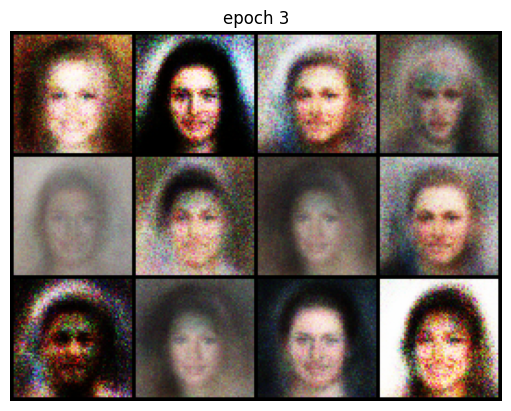

for epoch: 4/10... batch: 1... G-loss:1.498862385749817.... D-loss: 0.4959001839160919
for epoch: 4/10... batch: 51... G-loss:2.2281148433685303.... D-loss: 0.3511691689491272
for epoch: 4/10... batch: 101... G-loss:2.2563323974609375.... D-loss: 0.4696561396121979
for epoch: 4/10... batch: 151... G-loss:2.391801118850708.... D-loss: 0.3809109926223755
for epoch: 4/10... batch: 201... G-loss:2.1585166454315186.... D-loss: 0.3774471879005432
for epoch: 4/10... batch: 251... G-loss:2.2038631439208984.... D-loss: 0.38561901450157166
for epoch: 4/10... batch: 301... G-loss:2.327209949493408.... D-loss: 0.4696226119995117
for epoch: 4/10... batch: 351... G-loss:1.952987551689148.... D-loss: 0.42319369316101074
for epoch: 4/10... batch: 401... G-loss:2.2828383445739746.... D-loss: 0.376465380191803
for epoch: 4/10... batch: 451... G-loss:1.9192800521850586.... D-loss: 0.4089758098125458
for epoch: 4/10... batch: 501... G-loss:2.019496440887451.... D-loss: 0.41695261001586914
for epoch: 4/10.

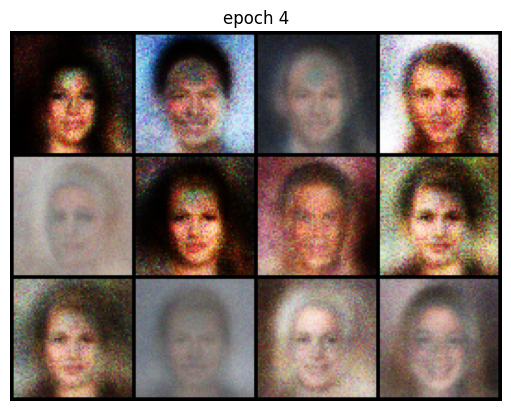

for epoch: 5/10... batch: 1... G-loss:2.2802889347076416.... D-loss: 0.5360960960388184
for epoch: 5/10... batch: 51... G-loss:1.7971582412719727.... D-loss: 0.47009962797164917
for epoch: 5/10... batch: 101... G-loss:1.9999806880950928.... D-loss: 0.5512565970420837
for epoch: 5/10... batch: 151... G-loss:1.7242456674575806.... D-loss: 0.43156397342681885
for epoch: 5/10... batch: 201... G-loss:1.5218822956085205.... D-loss: 0.4333832859992981
for epoch: 5/10... batch: 251... G-loss:2.322068691253662.... D-loss: 0.5376629829406738
for epoch: 5/10... batch: 301... G-loss:1.6686336994171143.... D-loss: 0.5607631206512451
for epoch: 5/10... batch: 351... G-loss:1.6493216753005981.... D-loss: 0.4286409318447113
for epoch: 5/10... batch: 401... G-loss:2.206770181655884.... D-loss: 0.433440238237381
for epoch: 5/10... batch: 451... G-loss:1.9467902183532715.... D-loss: 0.46881479024887085
for epoch: 5/10... batch: 501... G-loss:1.910836935043335.... D-loss: 0.4476199746131897
for epoch: 5/1

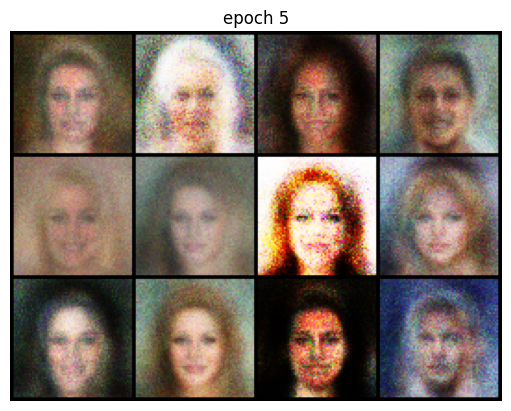

for epoch: 6/10... batch: 1... G-loss:1.9109110832214355.... D-loss: 0.4296468198299408
for epoch: 6/10... batch: 51... G-loss:2.074547290802002.... D-loss: 0.5338584184646606
for epoch: 6/10... batch: 101... G-loss:1.9391696453094482.... D-loss: 0.4473128914833069
for epoch: 6/10... batch: 151... G-loss:1.7385777235031128.... D-loss: 0.4757723808288574
for epoch: 6/10... batch: 201... G-loss:2.03644061088562.... D-loss: 0.49910885095596313
for epoch: 6/10... batch: 251... G-loss:2.494252920150757.... D-loss: 0.396434485912323
for epoch: 6/10... batch: 301... G-loss:1.9418036937713623.... D-loss: 0.44360753893852234
for epoch: 6/10... batch: 351... G-loss:1.8392798900604248.... D-loss: 0.5561056137084961
for epoch: 6/10... batch: 401... G-loss:1.7922863960266113.... D-loss: 0.4723861813545227
for epoch: 6/10... batch: 451... G-loss:1.828789472579956.... D-loss: 0.5066527724266052
for epoch: 6/10... batch: 501... G-loss:1.5235528945922852.... D-loss: 0.4658925533294678
for epoch: 6/10..

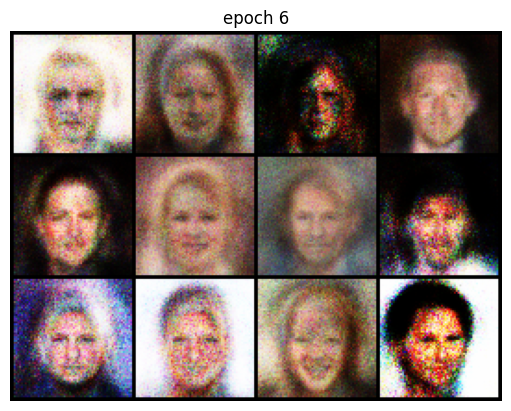

for epoch: 7/10... batch: 1... G-loss:1.8344073295593262.... D-loss: 0.43671077489852905
for epoch: 7/10... batch: 51... G-loss:1.8322447538375854.... D-loss: 0.4273834526538849
for epoch: 7/10... batch: 101... G-loss:2.2108664512634277.... D-loss: 0.4658406376838684
for epoch: 7/10... batch: 151... G-loss:2.0208799839019775.... D-loss: 0.4715014696121216
for epoch: 7/10... batch: 201... G-loss:1.5120177268981934.... D-loss: 0.45298200845718384
for epoch: 7/10... batch: 251... G-loss:1.934323787689209.... D-loss: 0.4538252651691437
for epoch: 7/10... batch: 301... G-loss:1.6403717994689941.... D-loss: 0.4913923442363739
for epoch: 7/10... batch: 351... G-loss:1.9852135181427002.... D-loss: 0.4478910267353058
for epoch: 7/10... batch: 401... G-loss:1.6343696117401123.... D-loss: 0.49495527148246765
for epoch: 7/10... batch: 451... G-loss:1.6383295059204102.... D-loss: 0.5123990774154663
for epoch: 7/10... batch: 501... G-loss:1.7630809545516968.... D-loss: 0.4891818165779114
for epoch: 

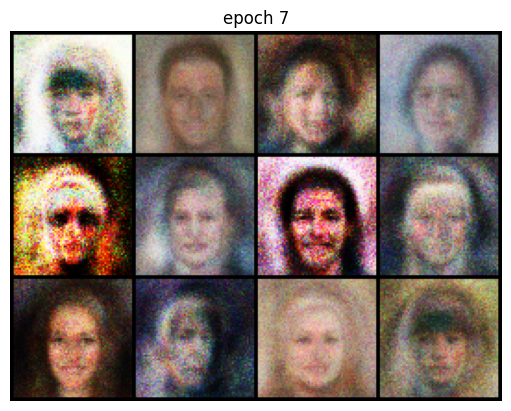

for epoch: 8/10... batch: 1... G-loss:1.426759958267212.... D-loss: 0.5559026002883911
for epoch: 8/10... batch: 51... G-loss:1.7101820707321167.... D-loss: 0.4925172030925751
for epoch: 8/10... batch: 101... G-loss:1.6515579223632812.... D-loss: 0.4107476472854614
for epoch: 8/10... batch: 151... G-loss:1.7504031658172607.... D-loss: 0.5260882377624512
for epoch: 8/10... batch: 201... G-loss:1.7686281204223633.... D-loss: 0.4755967855453491
for epoch: 8/10... batch: 251... G-loss:1.7510991096496582.... D-loss: 0.5183573961257935
for epoch: 8/10... batch: 301... G-loss:1.6440471410751343.... D-loss: 0.5578292608261108
for epoch: 8/10... batch: 351... G-loss:1.6125996112823486.... D-loss: 0.5031701326370239
for epoch: 8/10... batch: 401... G-loss:1.8033875226974487.... D-loss: 0.558448076248169
for epoch: 8/10... batch: 451... G-loss:1.859330654144287.... D-loss: 0.4985923171043396
for epoch: 8/10... batch: 501... G-loss:1.5216906070709229.... D-loss: 0.47030872106552124
for epoch: 8/10

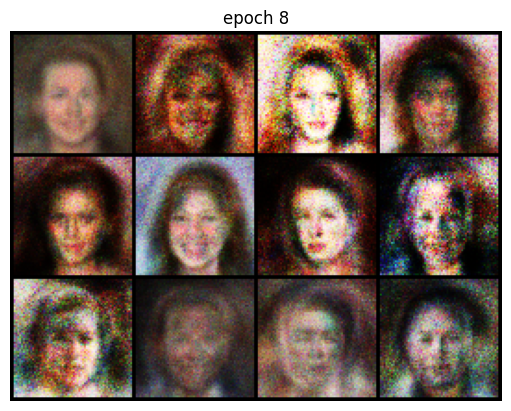

for epoch: 9/10... batch: 1... G-loss:1.5963408946990967.... D-loss: 0.5415763258934021
for epoch: 9/10... batch: 51... G-loss:1.461044192314148.... D-loss: 0.5075743198394775
for epoch: 9/10... batch: 101... G-loss:1.5414113998413086.... D-loss: 0.5256000757217407
for epoch: 9/10... batch: 151... G-loss:1.53043532371521.... D-loss: 0.5085383057594299
for epoch: 9/10... batch: 201... G-loss:1.4436180591583252.... D-loss: 0.5185973644256592
for epoch: 9/10... batch: 251... G-loss:1.7614154815673828.... D-loss: 0.5031057000160217
for epoch: 9/10... batch: 301... G-loss:1.3194050788879395.... D-loss: 0.5261250734329224
for epoch: 9/10... batch: 351... G-loss:1.5670382976531982.... D-loss: 0.5192821025848389
for epoch: 9/10... batch: 401... G-loss:1.4243314266204834.... D-loss: 0.5719664096832275
for epoch: 9/10... batch: 451... G-loss:1.5593881607055664.... D-loss: 0.5467754602432251
for epoch: 9/10... batch: 501... G-loss:1.6429123878479004.... D-loss: 0.4897369146347046
for epoch: 9/10.

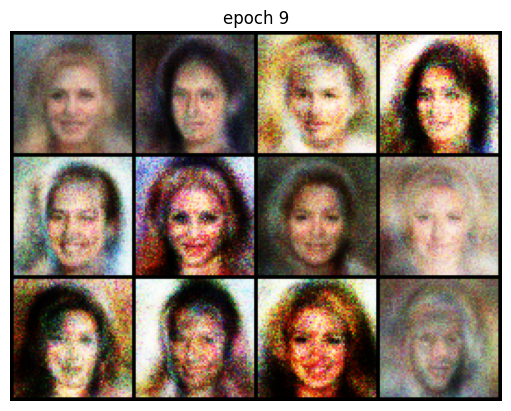

for epoch: 10/10... batch: 1... G-loss:1.8011093139648438.... D-loss: 0.4869651198387146
for epoch: 10/10... batch: 51... G-loss:1.573004961013794.... D-loss: 0.5397652387619019
for epoch: 10/10... batch: 101... G-loss:1.3822205066680908.... D-loss: 0.5351791977882385
for epoch: 10/10... batch: 151... G-loss:1.470496654510498.... D-loss: 0.5211065411567688
for epoch: 10/10... batch: 201... G-loss:1.3906408548355103.... D-loss: 0.5947657823562622
for epoch: 10/10... batch: 251... G-loss:1.6022334098815918.... D-loss: 0.4908924698829651
for epoch: 10/10... batch: 301... G-loss:1.5101102590560913.... D-loss: 0.5596033334732056
for epoch: 10/10... batch: 351... G-loss:1.5588598251342773.... D-loss: 0.5349569320678711
for epoch: 10/10... batch: 401... G-loss:1.4223377704620361.... D-loss: 0.5066226720809937
for epoch: 10/10... batch: 451... G-loss:1.4293124675750732.... D-loss: 0.5470210313796997
for epoch: 10/10... batch: 501... G-loss:1.4846038818359375.... D-loss: 0.5555559396743774
for 

In [ ]:
train(generator, discriminator, dataloader, epochs=10)

In [ ]:
!nvidia-smi